# 3D Protein & Molecular Visualization on Vulkan GPU (`vkshader` + `vkscipy` + `vkcolorcet`)

Inspired by Datoviz's Vulkan molecule showcase — renders real **RCSB Protein Data Bank (PDB)** macromolecules as **Z-buffered Blinn–Phong 3D shaded sphere impostors** (`kind='spheres'`) directly in a zero-copy Vulkan SPIR-V compute shader:
- **`6VXX`**: SARS-CoV-2 Spike Glycoprotein Trimer (**23,694 atoms**)
- **`6M0J`**: SARS-CoV-2 Spike RBD bound to Human **ACE2** Receptor
- **`4HHB`**: Human **Hemoglobin** tetramer (with Iron Heme groups)

Plus a Vulkan GPU **Protein Contact Distance Map** computed via `vkscipy.spatial.distance.cdist`!

In [1]:
import sys, time, urllib.request
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
import vknumpy as vnp
import vkpandas as vpd
import vkshader as vks
import vkscipy as vsp
import vkcolorcet as cc

bio_dir = Path.home() / ".cache/vkdata/biology"
bio_dir.mkdir(parents=True, exist_ok=True)

def load_pdb_gpu(pdb_id: str) -> vpd.DataFrame:
    p = bio_dir / f"{pdb_id}.pdb"
    if not p.is_file():
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{pdb_id}.pdb", p)
    xs, ys, zs, elem_ids, chain_ids, res_ids, is_ca = [], [], [], [], [], [], []
    elem_map = {"C": 0, "N": 1, "O": 2, "S": 3, "P": 4, "FE": 5, "ZN": 6}
    chain_map = {}
    with open(p) as f:
        for line in f:
            if line.startswith(("ATOM  ", "HETATM")):
                if line[17:20].strip() == "HOH":
                    continue
                xs.append(float(line[30:38]))
                ys.append(float(line[38:46]))
                zs.append(float(line[46:54]))
                el = line[76:78].strip().upper() or line[12:14].strip()[0].upper()
                ch = line[21].strip() or "A"
                if ch not in chain_map:
                    chain_map[ch] = len(chain_map)
                elem_ids.append(elem_map.get(el, 7))
                chain_ids.append(chain_map[ch])
                res_ids.append(int(line[22:26]))
                is_ca.append(1 if line[12:16].strip() == "CA" else 0)
    res_arr = np.array(res_ids, dtype=np.float32)
    res_bin = np.clip(np.round((res_arr - res_arr.min()) / max(res_arr.max() - res_arr.min(), 1.0) * 255.0), 0, 255).astype(np.int32)
    return vpd.DataFrame({
        "x": np.array(xs, dtype=np.float32),
        "y": np.array(ys, dtype=np.float32),
        "z": np.array(zs, dtype=np.float32),
        "element": np.array(elem_ids, dtype=np.int32),
        "chain": np.array(chain_ids, dtype=np.int32),
        "res_color": res_bin,
        "is_ca": np.array(is_ca, dtype=np.int32),
    })

spike_6vxx = load_pdb_gpu("6VXX")
ace2_6m0j  = load_pdb_gpu("6M0J")
hemo_4hhb  = load_pdb_gpu("4HHB")

print(f"6VXX (SARS-CoV-2 Spike Trimer): {len(spike_6vxx):,} atoms")
print(f"6M0J (Spike RBD + Human ACE2):  {len(ace2_6m0j):,} atoms")
print(f"4HHB (Human Hemoglobin):        {len(hemo_4hhb):,} atoms")

6VXX (SARS-CoV-2 Spike Trimer): 23,694 atoms
6M0J (Spike RBD + Human ACE2):  6,491 atoms
4HHB (Human Hemoglobin):        4,558 atoms


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


## 1. 3D Shaded Protein Gallery (Vulkan Blinn–Phong Sphere Impostors)

### What you're seeing:
- **Left — `6VXX` (SARS-CoV-2 Spike Trimer, 23,694 atoms)**: colored by **polypeptide chain** (showing the 3 intertwined trimer subunits).
- **Middle — `6M0J` (Spike RBD bound to Human ACE2)**: coral vs. teal clearly highlights the exact **binding interface** between the viral receptor-binding domain and the human ACE2 enzyme.
- **Right — `4HHB` (Human Hemoglobin)**: colored by **CPK chemical element** (**Carbon** light gray, **Nitrogen** blue, **Oxygen** red, **Sulfur** yellow, **Iron** rust-orange).

[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


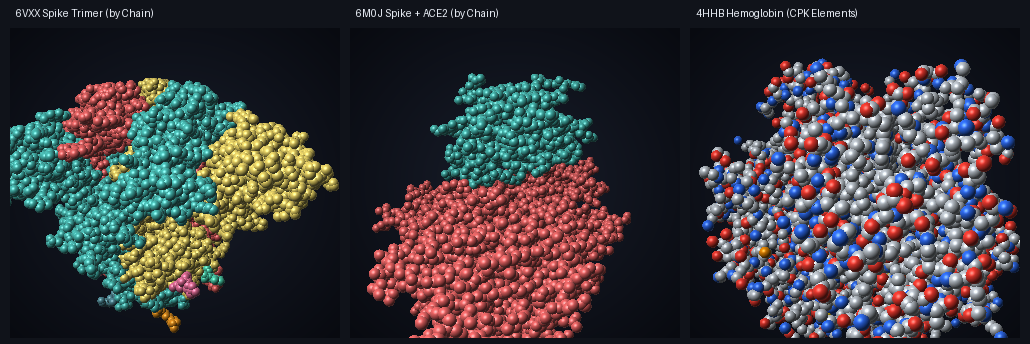

In [2]:
CPK_COLORS = ["#c8cfd8", "#3070ff", "#ff3b30", "#ffd60a", "#ff9500", "#e06633", "#9b59b6", "#32d7ff"]

im1 = vks.render_3d(spike_6vxx, "x", "y", "z", width=330, height=310, kind="spheres",
                    color_by="chain", color_key=cc.glasbey_dark[:8], basemap=None, yaw=0.6, pitch=0.35, dist=2.3, z_scale=0.80).to_pil()
im2 = vks.render_3d(ace2_6m0j, "x", "y", "z", width=330, height=310, kind="spheres",
                    color_by="chain", color_key=["#ff6b6b", "#4ecdc4", "#ffe66d", "#a29bfe"], basemap=None, yaw=0.9, pitch=0.30, dist=2.3, z_scale=0.85).to_pil()
im3 = vks.render_3d(hemo_4hhb, "x", "y", "z", width=330, height=310, kind="spheres",
                    color_by="element", color_key=CPK_COLORS, basemap=None, yaw=0.5, pitch=0.45, dist=2.2, z_scale=0.95).to_pil()

canvas = Image.new("RGB", (3 * 340 + 10, 344), (16, 19, 26))
draw = ImageDraw.Draw(canvas)
for i, (lbl, im) in enumerate([("6VXX Spike Trimer (by Chain)", im1), ("6M0J Spike + ACE2 (by Chain)", im2), ("4HHB Hemoglobin (CPK Elements)", im3)]):
    x0 = 10 + i * 340
    draw.text((x0 + 6, 7), lbl, fill=(235, 240, 248))
    canvas.paste(im.convert("RGB"), (x0, 28))
canvas

## 2. Interactive 3D Molecular Explorer (`6VXX` — 23,694 Atoms)

- **Drag** to orbit 360° around the molecule · **Shift+Drag / Right-Drag** to pan · **Scroll** to zoom into atomic pockets · **Double-click** to reset.
- Switch live between **Polypeptide Chain**, **CPK Chemical Element**, and **Residue Sequence (`vkcolorcet.turbo`)**, and adjust atom radius via **Z Height**.

In [3]:
vks.interact_3d(
    spike_6vxx, "x", "y", "z",
    width=780, height=540,
    kind="spheres",
    color_modes={
        "Polypeptide Chain (Trimer)": ("chain", cc.glasbey_dark[:8]),
        "CPK Element (C/N/O/S)": ("element", CPK_COLORS),
        "Residue Sequence (Turbo)": ("res_color", cc.turbo),
    },
    basemap=None,
    z_scale=0.80,
);

## 3. GPU Protein Contact Distance Map (`vkscipy.spatial.distance.cdist`)

Computes the full pairwise **C-alpha (backbone) Euclidean distance matrix** in Ångströms for Human Hemoglobin (`4HHB`) via Vulkan GPU GEMM (`vkscipy.spatial.distance.cdist`). Bright diagonal stripes reveal **alpha-helices**, and off-diagonal blocks reveal **inter-chain subunit contacts**!

GPU cdist on 574 C-alpha backbone atoms ((574, 574)) in 14.03 ms


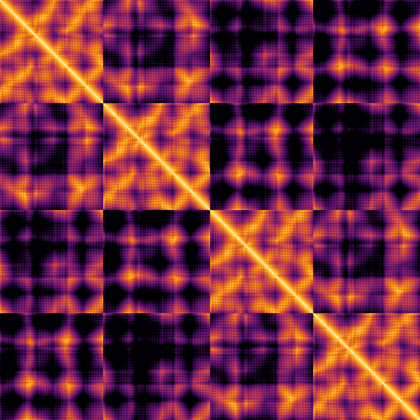

In [4]:
ca = hemo_4hhb[hemo_4hhb["is_ca"] == 1]
coords = np.column_stack([ca["x"].to_numpy(), ca["y"].to_numpy(), ca["z"].to_numpy()]).astype(np.float32)
t0 = time.perf_counter()
D = vsp.spatial.distance.cdist(coords, coords, metric="euclidean").to_numpy()
print(f"GPU cdist on {len(coords)} C-alpha backbone atoms ({D.shape}) in {(time.perf_counter()-t0)*1000:.2f} ms")

# Colorize distance map (0 .. 45 Angstroms) with reversed inferno so close contacts glow bright
norm = 1.0 - np.clip(D / 45.0, 0.0, 1.0)
lut = cc.get_rgb_lut("inferno")
rgb = lut[np.round(norm * 255.0).astype(np.int32)]
Image.fromarray(rgb, mode="RGB").resize((420, 420))